In [1]:
!pip install pandas mlxtend

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.4 MB ? eta -:--:--
   ----------------------- ---------------- 0.8/1.4 MB 1.9 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 2.2 MB/s  0:00:01



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



Encoded Dataset:

   Instant food products  UHT-milk  abrasive cleaner  artif. sweetener  \
0                  False     False             False             False   
1                  False     False             False             False   
2                  False     False             False             False   
3                  False     False             False             False   
4                  False     False             False             False   

   baby cosmetics   bags  baking powder  bathroom cleaner   beef  berries  \
0           False  False          False             False  False    False   
1           False  False          False             False  False    False   
2           False  False          False             False  False    False   
3           False  False          False             False  False    False   
4           False  False          False             False  False    False   

   ...  turkey  vinegar  waffles  whipped/sour cream  whisky  white bread

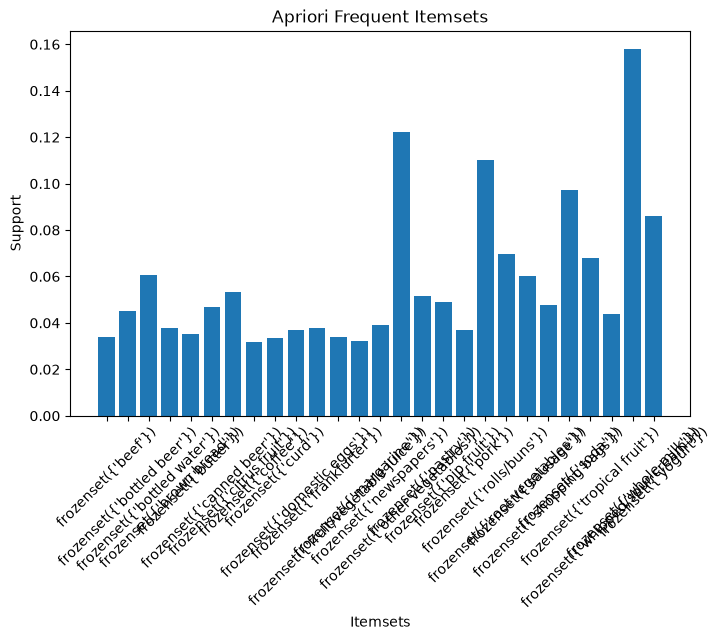

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

# Dataset
# transactions = [
#     ['Bread', 'Milk'],
#     ['Bread', 'Butter'],
#     ['Bread', 'Milk', 'Butter'],
#     ['Milk', 'Butter'],
#     ['Bread', 'Butter']
# ]



# Read dataset
gd = pd.read_csv("GD.csv")

# Create Transaction ID
gd['TransactionID'] = (
    gd['Member_number'].astype(str)
    + "_" +
    gd['Date'].astype(str)
)

# Group products purchased together
transactions = (
    gd.groupby('TransactionID')['itemDescription']
      .apply(list)
      .tolist()
)

# Encode transactions
te = TransactionEncoder()
te_array = te.fit(transactions).transform(transactions)

df = pd.DataFrame(
    te_array,
    columns=te.columns_
)

print("\nEncoded Dataset:\n")
print(df.head())


# Apriori
freq_items = apriori(df,
                     min_support=0.03,
                     use_colnames=True)

print(freq_items)

# Rules
rules = association_rules(
    freq_items,
    metric="confidence",
    min_threshold=0.1
)

print("\nRules Found:\n")
print(rules[['antecedents',
             'consequents',
             'support',
             'confidence',
             'lift']])

# Plot Frequent Itemsets
plt.figure(figsize=(8,5))
plt.bar(
    freq_items['itemsets'].astype(str),
    freq_items['support']
)

plt.title("Apriori Frequent Itemsets")
plt.xlabel("Itemsets")
plt.ylabel("Support")
plt.xticks(rotation=45)
plt.show()